# Figure 5 Supplement 1: Late bound slope by condition

The fitted bound time course (as in Figure 3C) for every condition of cohorts 1
and 2, with a test of the late part of the collapse in each condition.

**Fits** (`scripts/run_stopping_late_slope.py`): each subject's start height
(bound at step 1 relative to the plateau) and time of the fall to the plateau
are taken from their main fit to all of their data, as are sensory noise and
the non-decision time. Each condition's trials are then fit alone, with the
plateau, bound variability, guess, lapse and anticipation rates and the slope
of the bound after the fall free. The null model is the same with that slope
fixed at 0 (bound flat after the fall); the two are compared with a
likelihood-ratio test (χ², 1 df).

**Slope limit.** The slope is limited to ±0.15 log units per step (−78% to +350% per 10 steps). It is
estimated only from trials committed after the subject's time of fall, and in many conditions there are
few of these: at high SNR most decisions come before or near the fall, and some low-SNR conditions have
few trials. With little data after the fall the slope is barely constrained, and the fit often ends at
a limit (mostly the lower one) without a significant improvement over the flat bound. The summary therefore reports, per
condition, the median number of trials committed after the fall, the number of fits at the slope limit
(and how many of those are significant), and the counts of significant slopes; it does not report a
median slope, which in these conditions would mostly reflect the limit. The likelihood-ratio test is
unaffected (its null, slope 0, is inside the limits).

**Each panel:** every subject's bound relative to their plateau (thin blue), the
median across subjects (thick black), and the number of subjects whose bound
kept falling after the fall (slope < 0, p < 0.05) out of the subjects shown (labeled "late decline" in
the first panel).
Each subject's curve is drawn only up to the `DT_QUANTILE` quantile of their
decision times in that condition, so slopes estimated from few long trials are
not extrapolated; the median is taken over the subjects whose curves reach each
step and stops where fewer than half of them do.

Rows: cohort 1 (blocked SNR) low-SNR blocks 1–3 and high-SNR blocks 4–6;
cohort 2 (mixed SNR) blocks 1–3, low-SNR and high-SNR trials. Columns: reward
conditions (no penalty, coin penalty, step penalty). Subject-conditions whose
plateau sits at a fit limit (`get_plateau_at_limit`) are left out (counts
printed).

In [1]:
import sys

sys.path.insert(0, "..")


import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import CM, FS, FS_INSET, DATA_COLOR, MODEL_COLOR, add_row_xlabel, use_figure_style
from pigeon.stopping import get_log_h, get_plateau_at_limit, get_stopping_model_trials

PROCESSED = DATA_DIR

In [2]:
ALPHA = 0.05
STEPS = np.arange(1, 16)
DT_QUANTILE = 0.9
COLUMNS = ["No penalty", "Coin penalty", "Step penalty"]
ROWS = [
    ("Cohort 1, low SNR", "OL", ["B1", "B2", "B3"]),
    ("Cohort 1, high SNR", "OL", ["B4", "B5", "B6"]),
    ("Cohort 2, low-SNR trials", "MX", ["B1_lo", "B2_lo", "B3_lo"]),
    ("Cohort 2, high-SNR trials", "MX", ["B1_hi", "B2_hi", "B3_hi"]),
]

late = pd.read_pickle(PROCESSED / "stopping_late_slope.pkl")
main = pd.read_pickle(PROCESSED / "stopping_fits_main.pkl").groupby(["task", "subject_index"]).first()
late = late.join(main[["log_h_start", "knee"]], on=["task", "subject_index"])
print(
    f"{len(late)} subject x condition fits; raised: {int(late.error.notna().sum())}; "
    f"not converged: alternative {int((late.success_alt == False).sum())}, "  # noqa: E712
    f"null {int((late.success_null == False).sum())}"
)
# Each subject x condition's DT range, from the same trials the late-slope fits used
dt_max, n_after = {}, {}
for task, blocks in {"OL": [1, 2, 3, 4, 5, 6], "MX": [1, 2, 3]}.items():
    d = get_stopping_model_trials(task, blocks)
    if task == "MX":
        lo = np.isclose(d.snr.abs(), d.snr.abs().min())
        d["condition"] = d.condition + np.where(lo, "_lo", "_hi")
    dt_max[task] = d.groupby(["subject_index", "condition"]).DT.quantile(DT_QUANTILE)
    # Trials committed after the subject's time of fall (knee, from the main fit): the only trials that
    # constrain the slope after the fall
    knee = main.loc[task, "knee"]
    n_after[task] = (d.DT > d.subject_index.map(knee)).groupby([d.subject_index, d.condition]).sum()
dt_max = pd.concat(dt_max, names=["task"]).rename("dt_max")
n_after = pd.concat(n_after, names=["task"]).rename("n_after_fall")
late = late.join(dt_max, on=["task", "subject_index", "condition"]).join(
    n_after, on=["task", "subject_index", "condition"]
)
late["at_limit"] = get_plateau_at_limit(late)
late["collapsing"] = (late.late_slope < 0) & (late.p_value < ALPHA)
late["rising"] = (late.late_slope > 0) & (late.p_value < ALPHA)
SLOPE_LIMIT = 0.15  # limits of late_slope in the fits (log units per step)
late["at_slope_limit"] = np.isclose(late.late_slope.abs(), SLOPE_LIMIT, atol=1e-4)

rows = []
for label, task, conds in ROWS:
    for col, cond in zip(COLUMNS, conds):
        g = late[(late.task == task) & (late.condition == cond)]
        k = g[~g.at_limit & g.error.isna()]
        rows.append(
            {
                "row": label,
                "column": col,
                "subjects": len(k),
                "excluded (plateau at limit)": int(g.at_limit.sum()),
                "median trials": k.n_trials.median(),
                "median trials after the fall": k.n_after_fall.median(),
                f"median DT {DT_QUANTILE:.0%} quantile": k.dt_max.median(),
                "slope at limit": int(k.at_slope_limit.sum()),
                "slope at limit, p < 0.05": int((k.at_slope_limit & (k.p_value < ALPHA)).sum()),
                "collapsing (slope < 0, p < 0.05)": int(k.collapsing.sum()),
                "rising (slope > 0, p < 0.05)": int(k.rising.sum()),
            }
        )
summary = pd.DataFrame(rows)
print(
    f"Fits at the slope limit: {int(summary['slope at limit'].sum())} of {int(summary.subjects.sum())} "
    f"subject-conditions ({int(summary['slope at limit, p < 0.05'].sum())} of them significant)"
)
display(summary)

719 subject x condition fits; raised: 0; not converged: alternative 0, null 0


OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects
Fits at the slope limit: 271 of 695 subject-conditions (58 of them significant)


,row,column,subjects,excluded (plateau at limit),median trials,median trials after the fall,median DT 90% quantile,slope at limit,"slope at limit, p < 0.05","collapsing (slope < 0, p < 0.05)","rising (slope > 0, p < 0.05)"
0,"Cohort 1, low SNR",No penalty,58,2,108.0,46.0,5.0,28,15,24,0
1,"Cohort 1, low SNR",Coin penalty,59,1,64.0,44.0,11.0,11,7,32,0
2,"Cohort 1, low SNR",Step penalty,57,2,33.0,24.0,8.0,17,6,20,0
3,"Cohort 1, high SNR",No penalty,53,7,146.0,9.0,2.0,32,2,2,0
4,"Cohort 1, high SNR",Coin penalty,59,1,121.0,34.0,4.0,21,4,4,1
5,"Cohort 1, high SNR",Step penalty,60,0,78.0,10.5,3.0,28,1,1,0
6,"Cohort 2, low-SNR trials",No penalty,60,0,57.5,22.0,4.9,22,5,10,1
7,"Cohort 2, low-SNR trials",Coin penalty,57,3,47.0,25.0,8.0,11,4,19,0
8,"Cohort 2, low-SNR trials",Step penalty,58,2,23.5,14.5,6.0,19,3,13,0
9,"Cohort 2, high-SNR trials",No penalty,58,2,56.5,17.0,4.0,32,4,4,1


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


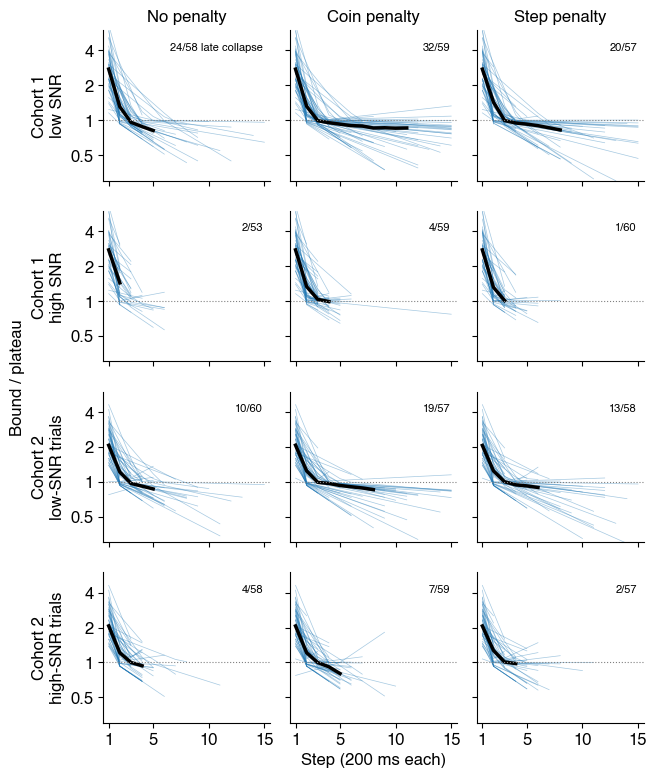

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05_S01.pdf (+ .png)


In [3]:
use_figure_style()
ROW_LABELS = ["Cohort 1\nlow SNR", "Cohort 1\nhigh SNR", "Cohort 2\nlow-SNR trials", "Cohort 2\nhigh-SNR trials"]

fig = plt.figure(figsize=(17.6 * CM, 20 * CM))
gs = gridspec.GridSpec(len(ROWS), 3, figure=fig, hspace=0.2, wspace=0.12, left=0.2, right=0.98, bottom=0.07, top=0.95)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(len(ROWS))])
for r, (label, task, conds) in enumerate(ROWS):
    for c, (col, cond) in enumerate(zip(COLUMNS, conds)):
        ax = axes[r, c]
        k = late[(late.task == task) & (late.condition == cond) & ~late.at_limit & late.error.isna()]
        shapes = np.exp(get_log_h(k, STEPS))
        shapes[STEPS[None, :] > k.dt_max.to_numpy()[:, None]] = np.nan  # only where the subject has trials
        ax.plot(STEPS, shapes.T, color=MODEL_COLOR, lw=0.5, alpha=0.4)
        enough = np.isfinite(shapes).sum(axis=0) >= len(k) / 2  # median where at least half the curves reach
        med = np.full(len(STEPS), np.nan)
        med[enough] = np.nanmedian(shapes[:, enough], axis=0)
        ax.plot(STEPS, med, "-", color=DATA_COLOR, lw=2.5)
        ax.axhline(1, color="0.5", ls=":", lw=0.8)
        # Subjects with a significant decline after the fall / subjects shown; spelled out in the first panel.
        ax.text(
            0.96,
            0.92,
            f"{int(k.collapsing.sum())}/{len(k)}" + (" late collapse" if r == 0 and c == 0 else ""),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=FS_INSET,
        )
        ax.set_yscale("log")
        ax.set_ylim(0.3, 6)
        ax.set_yticks([0.5, 1, 2, 4])
        ax.set_yticklabels(["0.5", "1", "2", "4"] if c == 0 else [])
        ax.minorticks_off()
        ax.set_xlim(0.5, 15.5)
        ax.set_xticks([1, 5, 10, 15])
        if r < len(ROWS) - 1:
            ax.set_xticklabels([])
        if r == 0:
            ax.set_title(col)
        if c == 0:
            ax.set_ylabel(ROW_LABELS[r])
        ax.spines[["top", "right"]].set_visible(False)

add_row_xlabel(fig, axes[-1], "Step (200 ms each)")
# One shared y label, left of the per-row cohort labels.
label_x0 = min(a.yaxis.label.get_window_extent().x0 for a in axes[:, 0])
label_x = fig.transFigure.inverted().transform((label_x0, 0))[0]
fig.text(
    label_x - 0.01,
    (axes[-1, 0].get_position().y0 + axes[0, 0].get_position().y1) / 2,
    "Bound / plateau",
    rotation=90,
    ha="right",
    va="center",
    fontsize=FS,
)

out = FIGURES_DIR / "Figure05_S01.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight")
fig.savefig(out.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {out} (+ .png)")